# AI-Enhanced Intrusion Detection System
## Complete Model Training, Evaluation & Comparison Notebook
### CICIDS2017 / UNSW-NB15 Datasets

**Models covered:**
- Random Forest · XGBoost · SVM · MLP
- 1D CNN · LSTM · CNN+LSTM Ensemble · Transformer

**Outputs:**
- Per-model accuracy, precision, recall, F1, FPR, AUC-ROC
- Confusion matrices · ROC curves · Feature importance
- Cross-dataset generalisation test (CICIDS2017 → UNSW-NB15)
- Saved model files ready for live IDS integration

---
> Run cells **top to bottom**.  
> First run: pip install cell takes ~3 min.  
> Training cells show estimated times for a standard laptop CPU.


## 1. Install & Import Dependencies

In [1]:
# Run once — installs all required packages
import subprocess, sys
packages = [
    "scikit-learn", "xgboost", "imbalanced-learn",
    "pandas", "numpy", "matplotlib", "seaborn",
    "tensorflow", "joblib", "tqdm",
]
for pkg in packages:
    subprocess.run([sys.executable, "-m", "pip", "install", pkg, "-q"], check=False)
print("All packages installed.")


All packages installed.


In [2]:
import warnings; warnings.filterwarnings("ignore")
import os, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# Scikit-learn
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, auc
)
# XGBoost
from xgboost import XGBClassifier
# Imbalanced-learn
from imblearn.over_sampling import SMOTE
# TensorFlow
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Dense, Dropout, BatchNormalization, Input,
    Conv1D, MaxPooling1D, GlobalAveragePooling1D,
    LSTM, MultiHeadAttention, LayerNormalization,
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow : {tf.__version__}")
print(f"NumPy      : {np.__version__}")
print(f"Pandas     : {pd.__version__}")
print("All imports OK.")


TensorFlow : 2.21.0
NumPy      : 1.26.4
Pandas     : 2.2.2
All imports OK.


## 2. Configuration — Set Your File Paths Here

In [3]:
# ── EDIT THESE TO MATCH WHERE YOU SAVED THE DATASETS ──────────────────────

# CICIDS2017  →  https://www.unb.ca/cic/datasets/ids-2017.html
CICIDS_FILES = [
    "../datas/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    "../datas/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "../datas/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv",
    # Uncomment for more attack types:
    "../datas/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv",
    "../datas/MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "../datas/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "../datas/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv",
    "../datas/MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv"
]

# UNSW-NB15  →  https://research.unsw.edu.au/projects/unsw-nb15-dataset
UNSW_TRAIN = "../datas/CSV Files/Training and Testing Sets/UNSW_NB15_training-set.csv"
UNSW_TEST  = "../datas/CSV Files/Training and Testing Sets/UNSW_NB15_testing-set.csv"

# Outputs
OUTPUT_DIR  = "models"
FIGURES_DIR = "figures"
os.makedirs(OUTPUT_DIR,  exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# Training settings
TEST_SIZE   = 0.20       # 80/20 split
MAX_SAMPLES = 200_000    # cap rows for laptop speed — set None to use all
APPLY_SMOTE = True       # balance minority classes
TIMESTEPS   = 10         # sequence length for LSTM / Transformer

print("Config ready.")
print(f"  Output  : {OUTPUT_DIR}/")
print(f"  Figures : {FIGURES_DIR}/")


Config ready.
  Output  : models/
  Figures : figures/


## 3. Load & Preprocess CICIDS2017

In [4]:
def load_cicids(file_paths, max_samples=None):
    dfs = []
    for path in file_paths:
        if not os.path.exists(path):
            print(f"  WARNING: not found — {path}")
            continue
        print(f"  Reading {path} ...")
        df = pd.read_csv(path, encoding="utf-8", low_memory=False)
        df.columns = df.columns.str.strip()
        dfs.append(df)
    if not dfs:
        raise FileNotFoundError(
            "No CICIDS2017 files loaded. Check CICIDS_FILES paths in Section 2."
        )
    df = pd.concat(dfs, ignore_index=True)
    print(f"  Raw rows: {len(df):,}")

    # Clean
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.dropna(inplace=True)

    # Find label column
    label_col = next((c for c in df.columns if c.strip().lower() == "label"), None)
    if label_col is None:
        raise ValueError(f"Label column not found. Columns: {list(df.columns)[:10]}")
    df.rename(columns={label_col: "Label"}, inplace=True)

    # Drop identifiers
    drop_cols = ["Flow ID","Source IP","Source Port",
                 "Destination IP","Destination Port","Timestamp"]
    df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)

    print(f"  After clean: {len(df):,} rows, {df.shape[1]-1} features")
    print("  Class distribution:")
    for cls, cnt in df["Label"].value_counts().items():
        print(f"    {cls:<45} {cnt:>8,}")

    if max_samples and len(df) > max_samples:
        df = df.groupby("Label", group_keys=False).apply(
            lambda x: x.sample(
                min(len(x), max(1, int(max_samples * len(x) / len(df)))),
                random_state=SEED
            )
        ).reset_index(drop=True)
        print(f"  Sampled to: {len(df):,} rows")
    return df

print("Loading CICIDS2017...")
df_cicids = load_cicids(CICIDS_FILES, max_samples=MAX_SAMPLES)
print(f"Final shape: {df_cicids.shape}")


Loading CICIDS2017...
  Reading ../datas/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv ...
  Reading ../datas/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv ...
  Reading ../datas/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv ...
  Reading ../datas/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv ...
  Reading ../datas/MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv ...
  Reading ../datas/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv ...
  Reading ../datas/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv ...
  Reading ../datas/MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv ...
  Raw rows: 2,830,743
  After clean: 2,827,876 rows, 77 features
  Class distribution:
    BENIGN                                        2,271,320
    DoS Hulk                                       230,124
    PortScan                                       158,804
    DDoS    

In [5]:
# Encode labels
le = LabelEncoder()
y_all = le.fit_transform(df_cicids["Label"])
X_all = df_cicids.drop(columns=["Label"]).values.astype(np.float32)

n_classes  = len(le.classes_)
n_features = X_all.shape[1]

print("Label map:")
for i, cls in enumerate(le.classes_):
    print(f"  {i:>2}: {cls}  ({np.sum(y_all==i):,})")

joblib.dump(le, f"{OUTPUT_DIR}/label_encoder.pkl")
print(f"\nn_features={n_features}  n_classes={n_classes}")


Label map:
   0: BENIGN  (160,637)
   1: Bot  (138)
   2: DDoS  (9,054)
   3: DoS GoldenEye  (727)
   4: DoS Hulk  (16,275)
   5: DoS Slowhttptest  (388)
   6: DoS slowloris  (409)
   7: FTP-Patator  (561)
   8: Heartbleed  (1)
   9: Infiltration  (2)
  10: PortScan  (11,231)
  11: SSH-Patator  (417)
  12: Web Attack � Brute Force  (106)
  13: Web Attack � Sql Injection  (1)
  14: Web Attack � XSS  (46)

n_features=77  n_classes=15


In [10]:
# Train / test split
# ── Fix: drop classes with fewer than 2 samples (can't stratify) ──────────
min_samples = 2
counts = np.bincount(y_all)
valid_mask = counts[y_all] >= min_samples
X_filtered = X_all[valid_mask]
y_filtered = y_all[valid_mask]

dropped = [le.classes_[i] for i, c in enumerate(counts) if c < min_samples]
if dropped:
    print(f"Dropped classes with < {min_samples} samples: {dropped}")
    print(f"Remaining samples: {len(X_filtered):,}")

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_filtered, y_filtered,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y_filtered        # now safe — all classes have >= 2 samples
)

# Scale
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_raw)
X_test_sc  = scaler.transform(X_test_raw)
joblib.dump(scaler, f"{OUTPUT_DIR}/scaler.pkl")

# SMOTE
if APPLY_SMOTE:
    print("Applying SMOTE ...")
    try:
        # Count only classes that actually exist in y_train
        unique_classes, class_counts = np.unique(y_train, return_counts=True)
        min_count = class_counts.min()
        min_class = unique_classes[class_counts.argmin()]
        print(f"  Smallest class: label {min_class} with {min_count} samples")

        k = min(3, min_count - 1)
        if k < 1:
            raise ValueError(
                f"Class {min_count} has too few samples for SMOTE"
            )
        sm = SMOTE(random_state=SEED, k_neighbors=k)
        X_tr, y_tr = sm.fit_resample(X_train_sc, y_train)
        print(f"  Before: {X_train_sc.shape[0]:,}  After: {X_tr.shape[0]:,}")
    except Exception as e:
        print(f"  SMOTE failed ({e}) — using original")
        X_tr, y_tr = X_train_sc, y_train
else:
    X_tr, y_tr = X_train_sc, y_train

# Update n_classes after filtering
n_classes  = len(np.unique(y_filtered))
n_features = X_train_sc.shape[1]

print(f"\nTrain: {X_tr.shape}  Test: {X_test_sc.shape}")
print(f"n_classes={n_classes}  n_features={n_features}")
print(f"Scaler saved -> {OUTPUT_DIR}/scaler.pkl")

Dropped classes with < 2 samples: ['Heartbleed', 'Web Attack � Sql Injection']
Remaining samples: 199,991
Applying SMOTE ...
  Smallest class: label 9 with 2 samples
  Before: 159,992  After: 1,670,617

Train: (1670617, 77)  Test: (39999, 77)
n_classes=13  n_features=77
Scaler saved -> models/scaler.pkl


In [23]:
# ── Re-encode all labels to gap-free integers ──────────────────────────────
# Required for Keras models (CNN, LSTM, Transformer)
# XGBoost also needs this — already handled in its cell
# RF, SVM, MLP tolerate gaps fine but consistent encoding doesn't hurt them

from sklearn.preprocessing import LabelEncoder as LE

le_remap = LE()
le_remap.fit(y_train)   # fit on train labels only

y_train_enc = le_remap.transform(y_train)   # use these for ALL models going forward
y_test_enc  = le_remap.transform(y_test)
y_tr_enc    = le_remap.transform(y_tr)      # this is the SMOTE-processed version

# Update n_classes to match
n_classes = len(le_remap.classes_)

joblib.dump(le_remap, f"{OUTPUT_DIR}/label_encoder_remap.pkl")

print("Gap-free label encoding applied:")
print(f"  Original labels : {sorted(np.unique(y_train))}")
print(f"  Re-encoded      : {sorted(np.unique(y_train_enc))}")
print(f"  n_classes       : {n_classes}")

Gap-free label encoding applied:
  Original labels : [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14]
  Re-encoded      : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
  n_classes       : 13


## 4. Metrics & Plotting Helpers

In [11]:
results = {}   # stores all model outputs

def evaluate(name, y_true, y_pred, y_prob=None, t_train=None, t_infer=None):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec  = recall_score(y_true, y_pred,    average="weighted", zero_division=0)
    f1   = f1_score(y_true, y_pred,        average="weighted", zero_division=0)

    cm   = confusion_matrix(y_true, y_pred)
    fp   = cm.sum(axis=0) - np.diag(cm)
    fn_  = cm.sum(axis=1) - np.diag(cm)
    tn   = cm.sum() - (fp + fn_ + np.diag(cm))
    fpr  = np.mean(fp / (fp + tn + 1e-9))

    auc_val = None
    if y_prob is not None:
        try:
            auc_val = roc_auc_score(
                to_categorical(y_true, n_classes), y_prob,
                multi_class="ovr", average="weighted"
            )
        except Exception:
            pass

    results[name] = dict(
        accuracy=acc, precision=prec, recall=rec,
        f1=f1, fpr=fpr, auc=auc_val,
        t_train=t_train, t_infer=t_infer,
        y_pred=y_pred, y_prob=y_prob, y_true=y_true,
    )

    sep = "─" * 52
    print(f"\n{sep}")
    print(f"  {name}")
    print(sep)
    print(f"  Accuracy  : {acc*100:.2f}%")
    print(f"  Precision : {prec*100:.2f}%")
    print(f"  Recall    : {rec*100:.2f}%")
    print(f"  F1 Score  : {f1*100:.2f}%")
    print(f"  FPR       : {fpr*100:.2f}%")
    if auc_val: print(f"  AUC-ROC   : {auc_val:.4f}")
    if t_train: print(f"  Train time: {t_train:.1f}s")
    if t_infer: print(f"  Infer/sample: {t_infer*1000:.2f}ms")


def plot_cm(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    cm_n = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-9)
    fig, ax = plt.subplots(figsize=(max(7, n_classes), max(5, n_classes-1)))
    sns.heatmap(cm_n, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(f"Confusion Matrix — {name}", fontsize=12)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.xticks(rotation=45, ha="right", fontsize=7)
    plt.yticks(fontsize=7)
    plt.tight_layout()
    path = f"{FIGURES_DIR}/cm_{name.lower().replace(' ','_').replace('+','')}.png"
    plt.savefig(path, dpi=150)
    plt.show()
    print(f"Saved -> {path}")


def plot_training_curves(name, history):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(history.history["loss"],     label="Train")
    a1.plot(history.history["val_loss"], label="Val")
    a1.set_title(f"{name} — Loss"); a1.legend()
    a2.plot(history.history["accuracy"],     label="Train")
    a2.plot(history.history["val_accuracy"], label="Val")
    a2.set_title(f"{name} — Accuracy"); a2.legend()
    plt.tight_layout()
    path = f"{FIGURES_DIR}/curves_{name.lower().replace(' ','_')}.png"
    plt.savefig(path, dpi=150)
    plt.show()


COLORS = ["#378ADD","#1D9E75","#D85A30","#7F77DD",
          "#639922","#BA7517","#D4537E","#555555"]

CALLBACKS = [
    EarlyStopping(monitor="val_loss", patience=5,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                      patience=3, verbose=1),
]

print("Helpers ready.")


Helpers ready.


## 5. Model 1 — Random Forest
*~2–8 min on laptop*

In [12]:
print("Training Random Forest ...")
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=200, n_jobs=-1,
    random_state=SEED, class_weight="balanced"
)
rf.fit(X_tr, y_tr)
t_train = time.time() - t0

t1 = time.time()
rf_pred = rf.predict(X_test_sc)
rf_prob = rf.predict_proba(X_test_sc)
t_infer = (time.time() - t1) / len(X_test_sc)

joblib.dump(rf, f"{OUTPUT_DIR}/rf_model.pkl")
evaluate("Random Forest", y_test, rf_pred, rf_prob, t_train, t_infer)


Training Random Forest ...

────────────────────────────────────────────────────
  Random Forest
────────────────────────────────────────────────────
  Accuracy  : 99.41%
  Precision : 99.69%
  Recall    : 99.41%
  F1 Score  : 99.53%
  FPR       : 0.07%
  Train time: 755.4s
  Infer/sample: 0.04ms


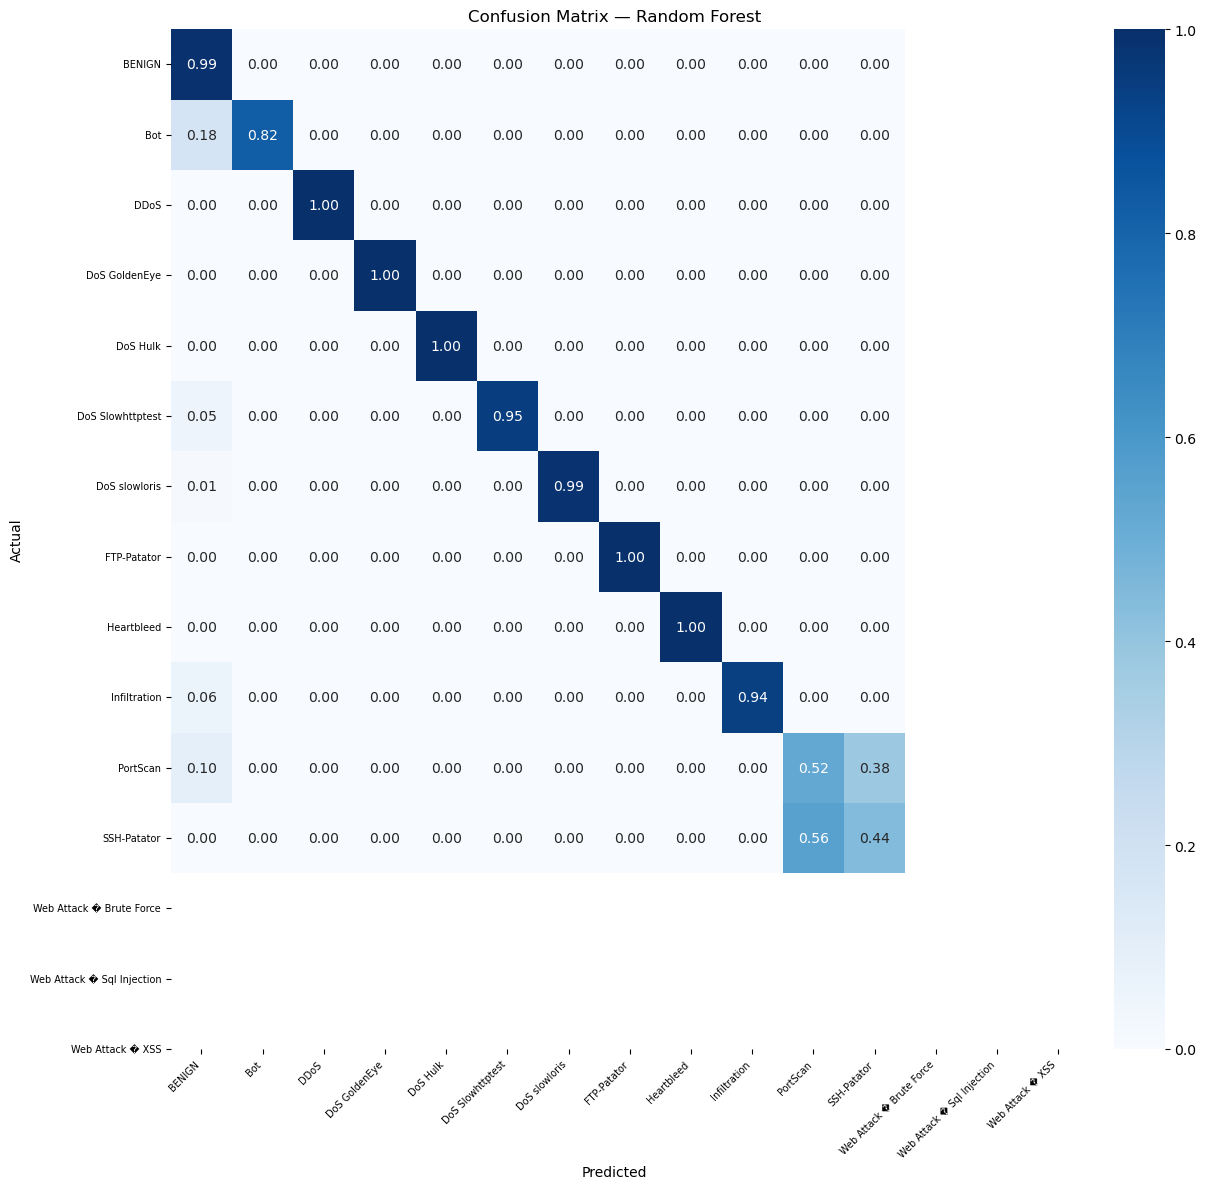

Saved -> figures/cm_random_forest.png


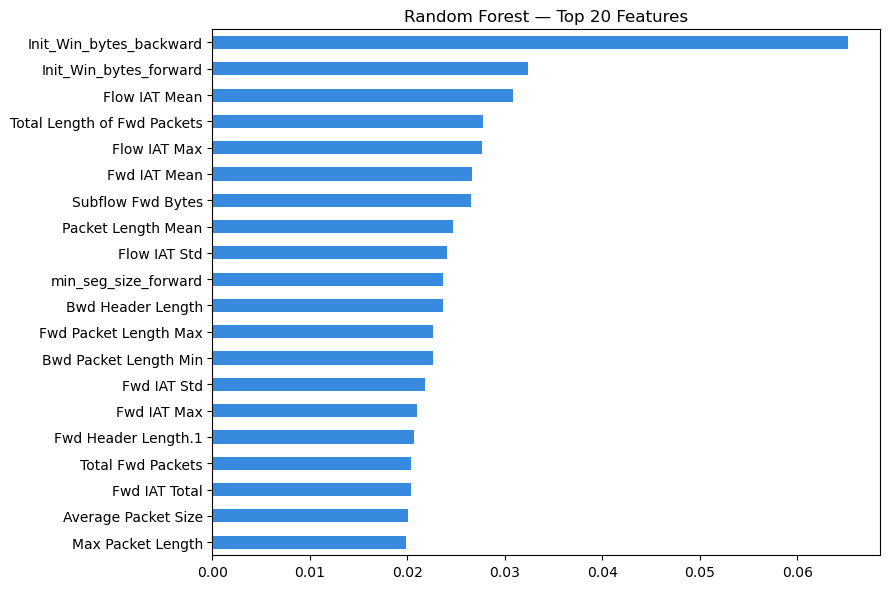

In [13]:
plot_cm("Random Forest", y_test, rf_pred)

# Feature importance
feat_names = df_cicids.drop(columns=["Label"]).columns
imp = pd.Series(rf.feature_importances_, index=feat_names).nlargest(20)
fig, ax = plt.subplots(figsize=(9,6))
imp.sort_values().plot(kind="barh", ax=ax, color="#378ADD")
ax.set_title("Random Forest — Top 20 Features")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/rf_features.png", dpi=150)
plt.show()


## 6. Model 2 — XGBoost
*~3–10 min*

In [25]:
# XGBoost — use same gap-free encoding
print("Training XGBoost ...")
t0 = time.time()
xgb_model = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    tree_method="hist", eval_metric="mlogloss",
    random_state=SEED, n_jobs=-1,
    use_label_encoder=False,
)
xgb_model.fit(
    X_tr, y_tr_enc,
    eval_set=[(X_test_sc, y_test_enc)],
    verbose=100
)
t_train = time.time() - t0

t1 = time.time()
xgb_pred = xgb_model.predict(X_test_sc)
xgb_prob = xgb_model.predict_proba(X_test_sc)
t_infer  = (time.time() - t1) / len(X_test_sc)

joblib.dump(xgb_model, f"{OUTPUT_DIR}/xgb_model.pkl")
evaluate("XGBoost", y_test_enc, xgb_pred, xgb_prob, t_train, t_infer)


# # ── Re-encode labels to fill gaps left by dropped classes ─────────────────
# # (XGBoost requires 0,1,2...n with no gaps — RF doesn't, XGB does)
# le2 = LabelEncoder()
# y_train_xgb = le2.fit_transform(y_train)
# y_test_xgb  = le2.transform(y_test)

# print("XGBoost label mapping (gap-free):")
# for orig, new in zip(le2.classes_, range(len(le2.classes_))):
#     print(f"  original label {orig} → xgb label {new}  ({le.classes_[orig]})")

# print("\nTraining XGBoost ...")
# t0 = time.time()
# xgb_model = XGBClassifier(
#     n_estimators=300, max_depth=6, learning_rate=0.1,
#     subsample=0.8, colsample_bytree=0.8,
#     tree_method="hist", eval_metric="mlogloss",
#     random_state=SEED, n_jobs=-1,
#     use_label_encoder=False,
# )
# xgb_model.fit(
#     X_tr, le2.transform(y_tr),     # re-encode training set too
#     eval_set=[(X_test_sc, y_test_xgb)],
#     verbose=100
# )
# t_train = time.time() - t0

# t1 = time.time()
# xgb_pred_enc = xgb_model.predict(X_test_sc)
# xgb_prob     = xgb_model.predict_proba(X_test_sc)
# t_infer      = (time.time() - t1) / len(X_test_sc)

# # Decode predictions back to original label space for consistent evaluation
# xgb_pred = le2.inverse_transform(xgb_pred_enc)

# joblib.dump(xgb_model, f"{OUTPUT_DIR}/xgb_model.pkl")
# joblib.dump(le2,       f"{OUTPUT_DIR}/label_encoder_xgb.pkl")

# evaluate("XGBoost", y_test, xgb_pred, xgb_prob, t_train, t_infer)

Training XGBoost ...
[0]	validation_0-mlogloss:2.11826
[100]	validation_0-mlogloss:0.01865
[200]	validation_0-mlogloss:0.01152
[299]	validation_0-mlogloss:0.01119

────────────────────────────────────────────────────
  XGBoost
────────────────────────────────────────────────────
  Accuracy  : 99.78%
  Precision : 99.80%
  Recall    : 99.78%
  F1 Score  : 99.79%
  FPR       : 0.03%
  Train time: 1100.1s
  Infer/sample: 0.06ms


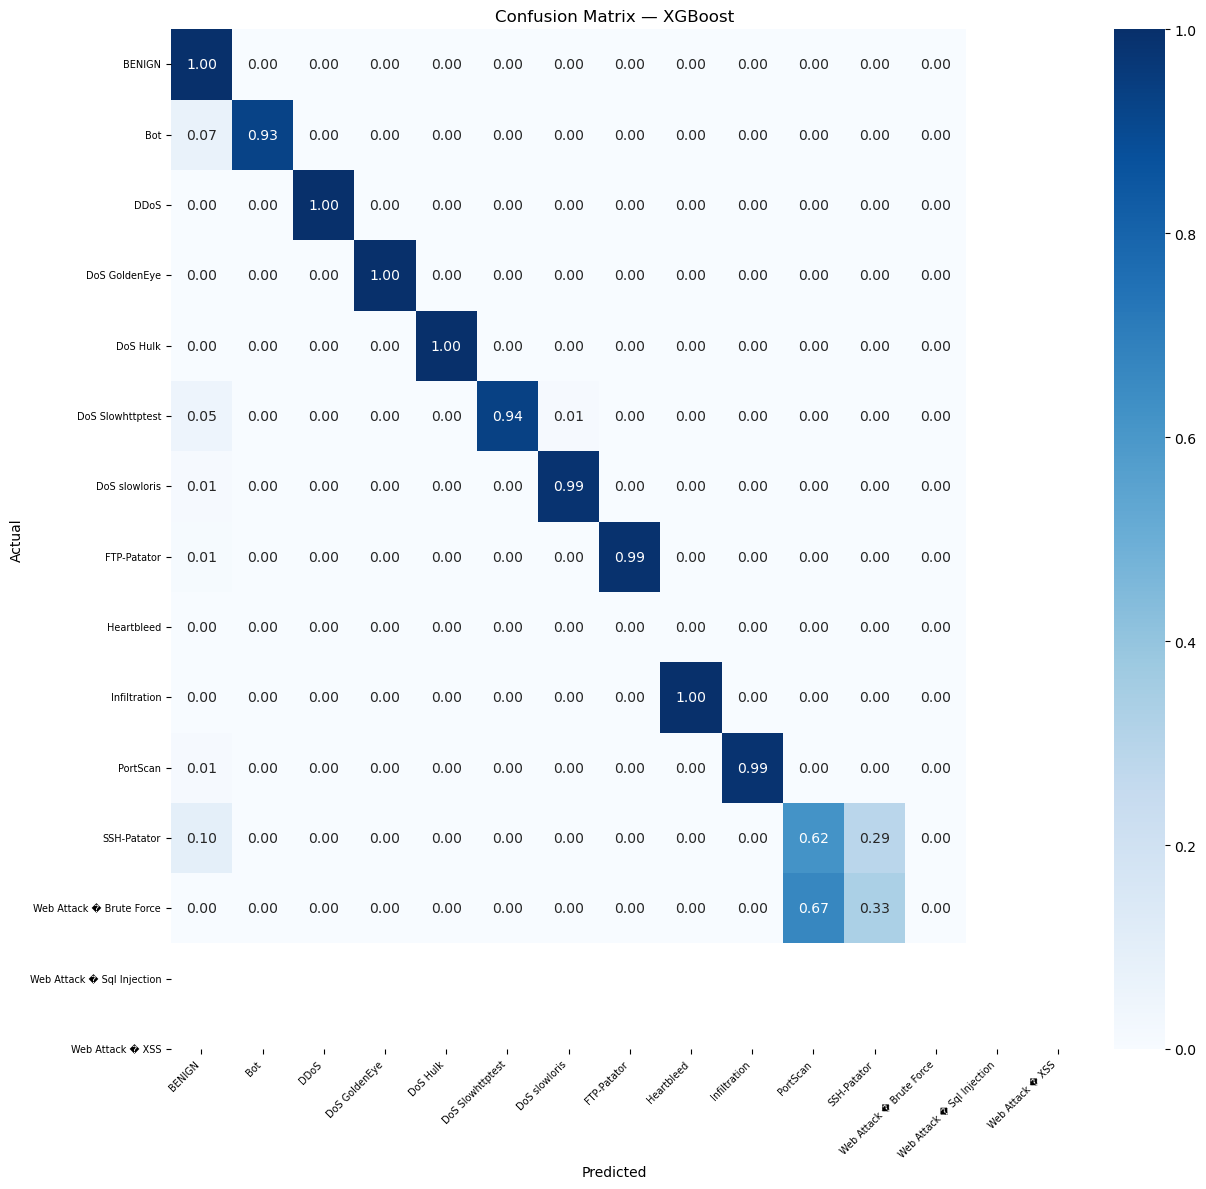

Saved -> figures/cm_xgboost.png


In [26]:
plot_cm("XGBoost", y_test, xgb_pred)


## 7. Model 3 — SVM
*~5–20 min (uses 30k sample — SVM doesn't scale)*

In [27]:
SVM_N = 30_000
idx = np.random.choice(len(X_tr), min(SVM_N, len(X_tr)), replace=False)
print(f"SVM sample: {len(idx):,} rows")

t0 = time.time()
svm = SVC(kernel="rbf", C=1.0, gamma="scale",
          probability=True, random_state=SEED,
          class_weight="balanced", cache_size=500)
svm.fit(X_tr[idx], y_tr[idx])
t_train = time.time() - t0

t1 = time.time()
svm_pred = svm.predict(X_test_sc)
svm_prob = svm.predict_proba(X_test_sc)
t_infer  = (time.time() - t1) / len(X_test_sc)

joblib.dump(svm, f"{OUTPUT_DIR}/svm_model.pkl")
evaluate("SVM", y_test, svm_pred, svm_prob, t_train, t_infer)


SVM sample: 30,000 rows

────────────────────────────────────────────────────
  SVM
────────────────────────────────────────────────────
  Accuracy  : 72.87%
  Precision : 92.58%
  Recall    : 72.87%
  F1 Score  : 79.22%
  FPR       : 2.15%
  Train time: 139.4s
  Infer/sample: 8.23ms


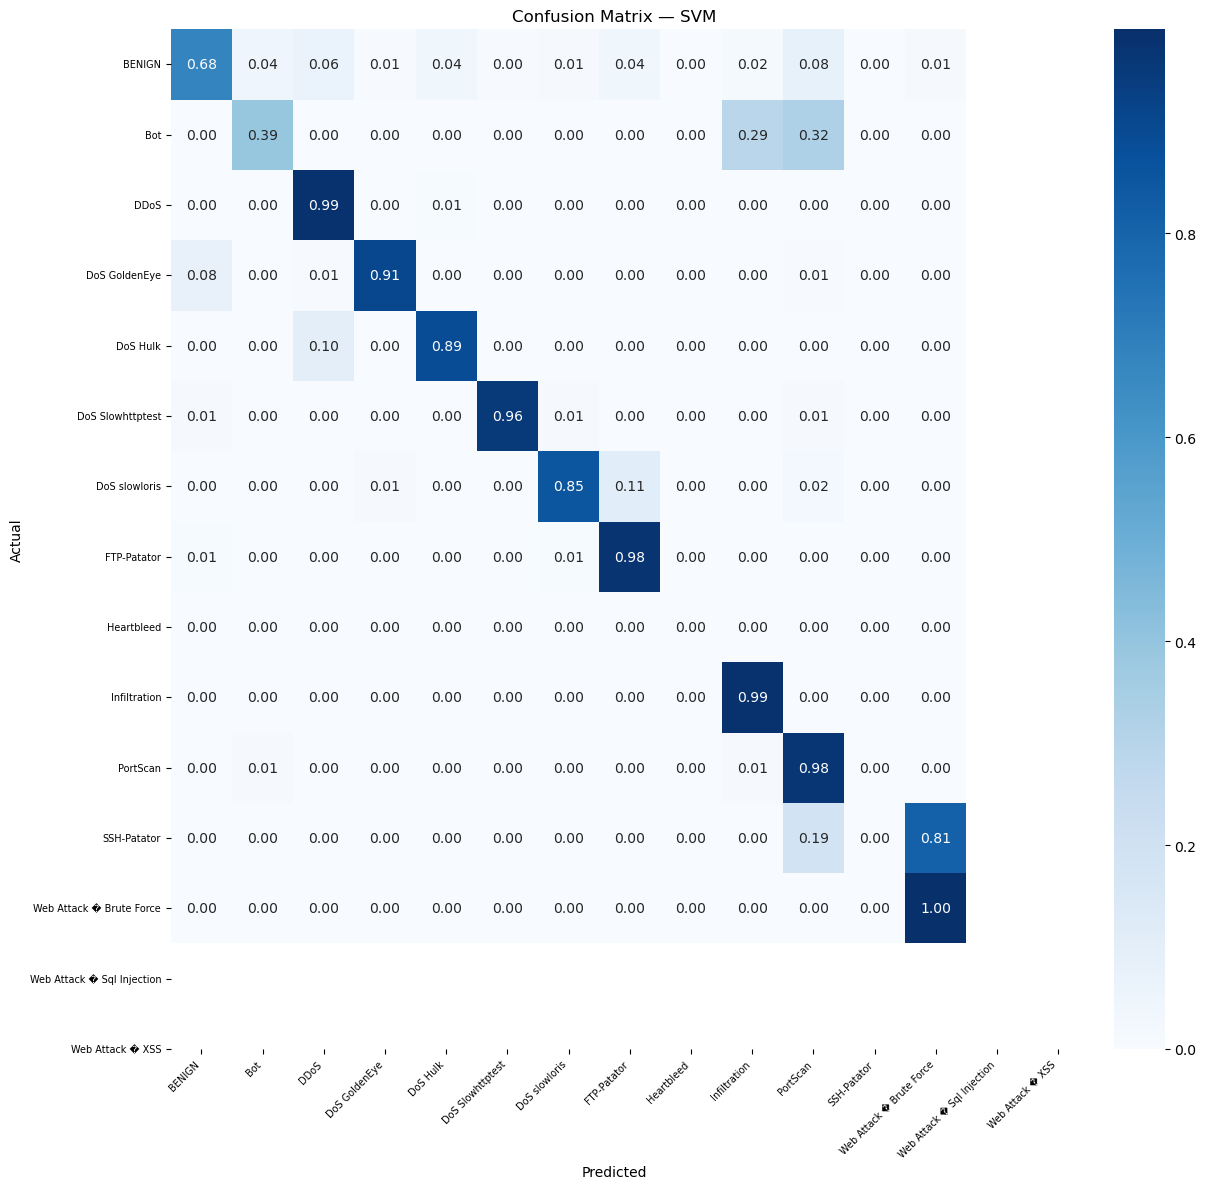

Saved -> figures/cm_svm.png


In [28]:
plot_cm("SVM", y_test, svm_pred)


## 8. Model 4 — MLP (Basic Neural Net)
*~5–15 min*

In [29]:
print("Training MLP ...")
t0 = time.time()
mlp = MLPClassifier(
    hidden_layer_sizes=(256, 128, 64),
    activation="relu", solver="adam",
    alpha=1e-4, batch_size=512,
    learning_rate="adaptive", max_iter=50,
    early_stopping=True, validation_fraction=0.1,
    random_state=SEED, verbose=True,
)
mlp.fit(X_tr, y_tr)
t_train = time.time() - t0

t1 = time.time()
mlp_pred = mlp.predict(X_test_sc)
mlp_prob = mlp.predict_proba(X_test_sc)
t_infer  = (time.time() - t1) / len(X_test_sc)

joblib.dump(mlp, f"{OUTPUT_DIR}/mlp_model.pkl")
evaluate("MLP", y_test, mlp_pred, mlp_prob, t_train, t_infer)


Training MLP ...
Iteration 1, loss = 0.20707719
Validation score: 0.919838
Iteration 2, loss = 0.15514844
Validation score: 0.922544
Iteration 3, loss = 0.14710553
Validation score: 0.942644
Iteration 4, loss = 0.14140927
Validation score: 0.942309
Iteration 5, loss = 0.13565070
Validation score: 0.941980
Iteration 6, loss = 0.13359454
Validation score: 0.941321
Iteration 7, loss = 0.13091387
Validation score: 0.939651
Iteration 8, loss = 0.13034694
Validation score: 0.940669
Iteration 9, loss = 0.12903185
Validation score: 0.940950
Iteration 10, loss = 0.12822278
Validation score: 0.942674
Iteration 11, loss = 0.12740054
Validation score: 0.944488
Iteration 12, loss = 0.12499323
Validation score: 0.944601
Iteration 13, loss = 0.12338380
Validation score: 0.946726
Iteration 14, loss = 0.12076027
Validation score: 0.945104
Iteration 15, loss = 0.11977790
Validation score: 0.944278
Iteration 16, loss = 0.11841532
Validation score: 0.944637
Iteration 17, loss = 0.11814366
Validation score

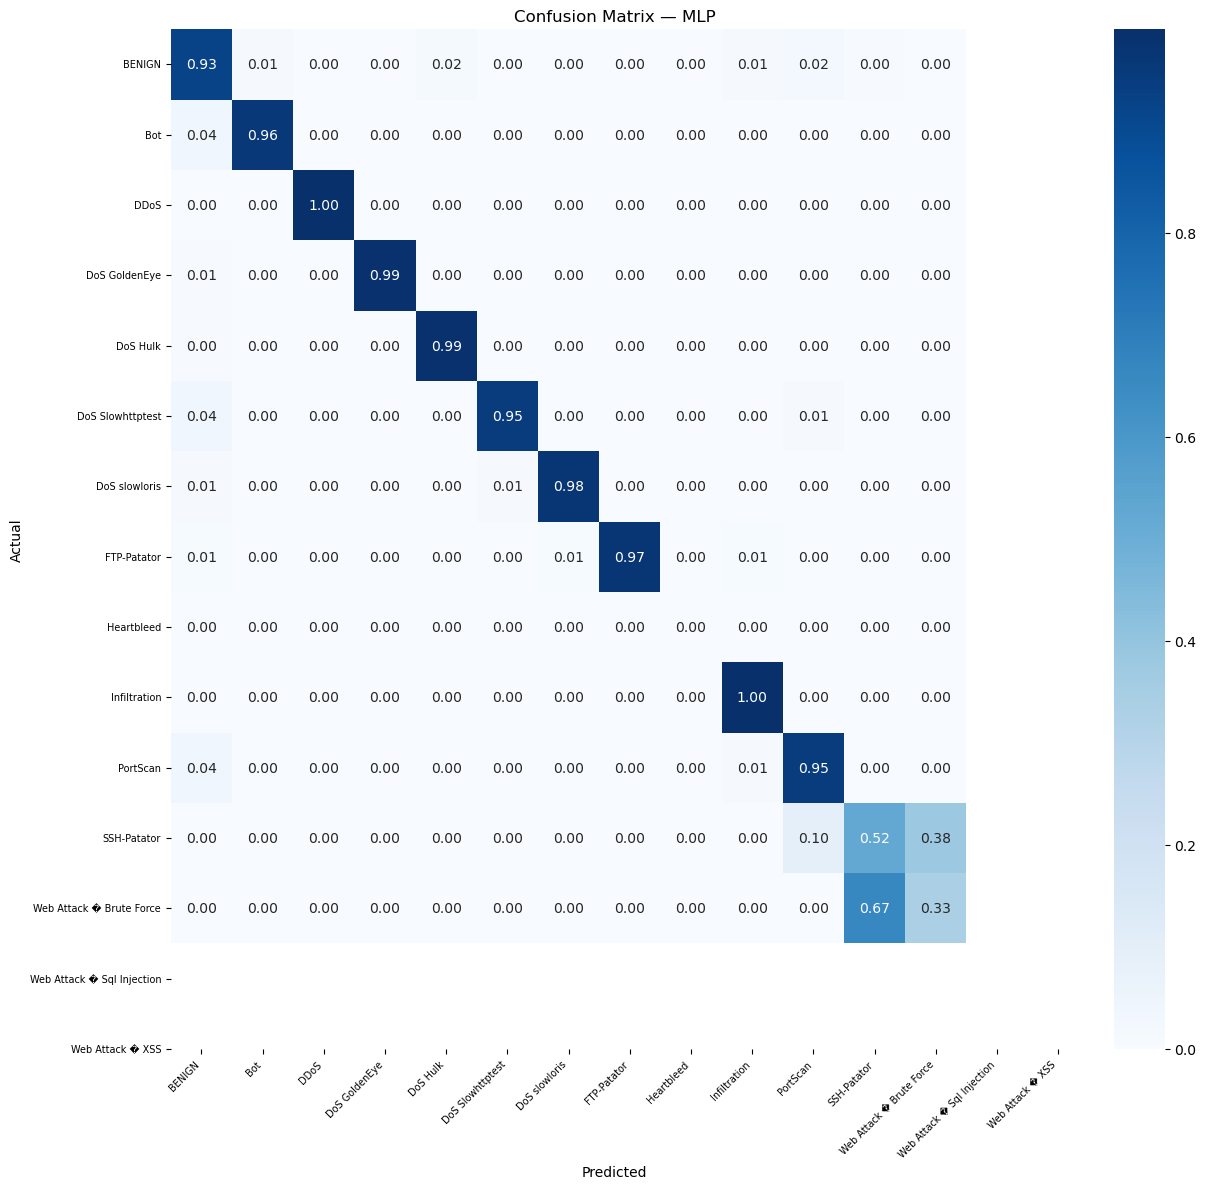

Saved -> figures/cm_mlp.png


In [30]:
plot_cm("MLP", y_test, mlp_pred)


## 9. Model 5 — 1D CNN
*~10–25 min on CPU*

In [31]:
def build_cnn(n_feat, n_cls):
    m = Sequential([
        Input(shape=(n_feat, 1)),
        Conv1D(64,  kernel_size=3, activation="relu", padding="same"),
        BatchNormalization(),
        MaxPooling1D(2),
        Conv1D(128, kernel_size=3, activation="relu", padding="same"),
        BatchNormalization(),
        Conv1D(64,  kernel_size=3, activation="relu", padding="same"),
        GlobalAveragePooling1D(),
        Dropout(0.3),
        Dense(128, activation="relu"),
        Dropout(0.3),
        Dense(n_cls, activation="softmax"),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
    return m

cnn = build_cnn(n_features, n_classes)
cnn.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)                    │ (None, 77, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 77, 64)              │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_2 (MaxPooling1D)       │ (None, 38, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_7 (Conv1D)                    │ (None, 38, 128)             │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 38, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_8 (Conv1D)                    │ (None, 38, 64)              │          24,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d_2           │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 13)                  │           1,677 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 60,365 (235.80 KB)

 Trainable params: 59,981 (234.30 KB)

 Non-trainable params: 384 (1.50 KB)

In [32]:
X_tr_cnn   = X_tr.reshape(-1, n_features, 1)
X_test_cnn = X_test_sc.reshape(-1, n_features, 1)

# Rebuild CNN with updated n_classes (in case you changed it above)
cnn = build_cnn(n_features, n_classes)

print("Training CNN ...")
t0 = time.time()
cnn_hist = cnn.fit(
    X_tr_cnn, y_tr_enc,          # ← use gap-free encoded labels
    epochs=30, batch_size=512,
    validation_split=0.1,
    callbacks=CALLBACKS, verbose=1,
)
t_train = time.time() - t0

t1 = time.time()
cnn_prob = cnn.predict(X_test_cnn, batch_size=512, verbose=0)
cnn_pred = np.argmax(cnn_prob, axis=1)
t_infer  = (time.time() - t1) / len(X_test_sc)

cnn.save(f"{OUTPUT_DIR}/cnn_model.h5")
print(f"Saved -> {OUTPUT_DIR}/cnn_model.h5")

# Evaluate against original y_test for consistent metrics with RF/XGBoost
evaluate("CNN", y_test_enc, cnn_pred, cnn_prob, t_train, t_infer)

Training CNN ...
Epoch 1/30
2937/2937 ━━━━━━━━━━━━━━━━━━━━ 305s 102ms/step - accuracy: 0.9487 - loss: 0.1759 - val_accuracy: 0.2097 - val_loss: 7.4810 - learning_rate: 0.0010
Epoch 2/30
2937/2937 ━━━━━━━━━━━━━━━━━━━━ 303s 103ms/step - accuracy: 0.9822 - loss: 0.0665 - val_accuracy: 0.2126 - val_loss: 7.3785 - learning_rate: 0.0010
Epoch 3/30
2937/2937 ━━━━━━━━━━━━━━━━━━━━ 334s 114ms/step - accuracy: 0.9841 - loss: 0.0576 - val_accuracy: 0.2134 - val_loss: 6.3331 - learning_rate: 0.0010
Epoch 4/30
2937/2937 ━━━━━━━━━━━━━━━━━━━━ 299s 102ms/step - accuracy: 0.9852 - loss: 0.0531 - val_accuracy: 0.2106 - val_loss: 7.8117 - learning_rate: 0.0010
Epoch 5/30
2937/2937 ━━━━━━━━━━━━━━━━━━━━ 299s 102ms/step - accuracy: 0.9864 - loss: 0.0480 - val_accuracy: 0.2138 - val_loss: 7.5390 - learning_rate: 0.0010
Epoch 6/30
2937/2937 ━━━━━━━━━━━━━━━━━━━━ 314s 107ms/step - accuracy: 0.9868 - loss: 0.0466 - val_accuracy: 0.2114 - val_loss: 6.3285 - learning_rate: 0.0010
Epoch 7/30
2937/2937 ━━━━━━━━━━━━━━

Saved -> models/cnn_model.h5

────────────────────────────────────────────────────
  CNN
────────────────────────────────────────────────────
  Accuracy  : 94.84%
  Precision : 96.30%
  Recall    : 94.84%
  F1 Score  : 95.32%
  FPR       : 0.59%
  Train time: 12263.6s
  Infer/sample: 0.06ms


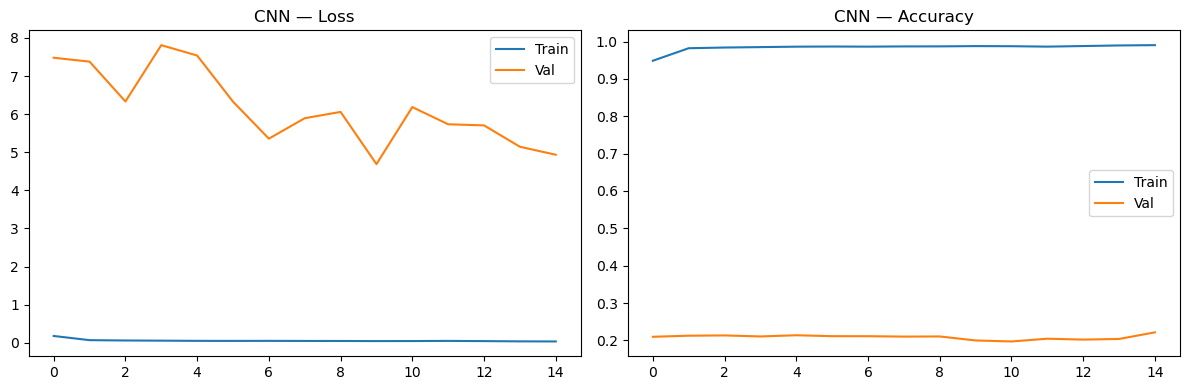

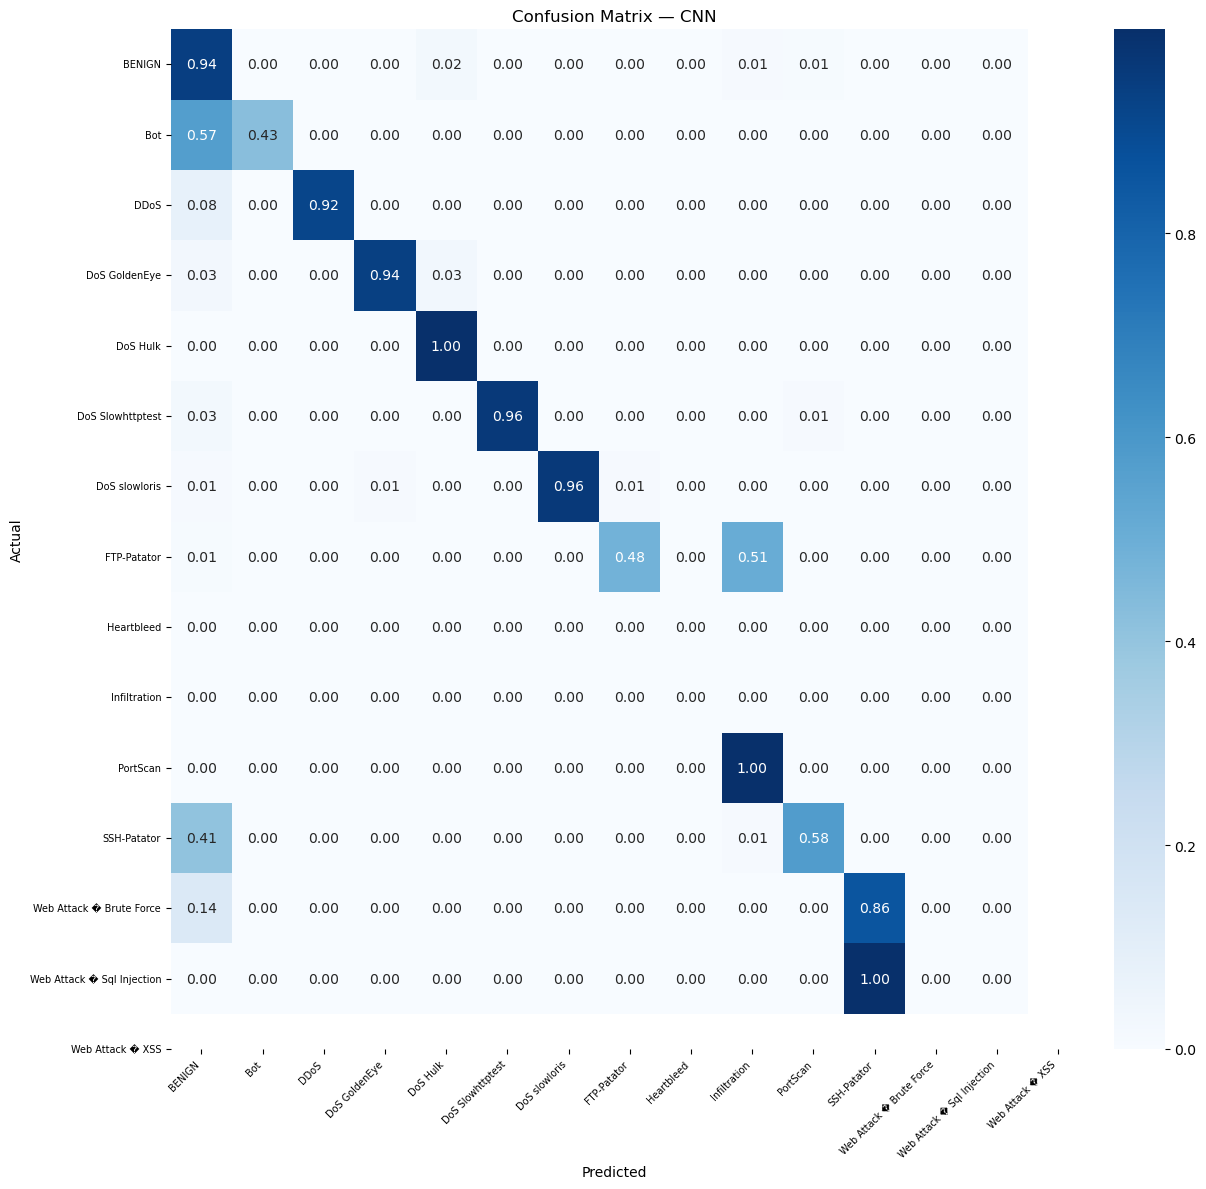

Saved -> figures/cm_cnn.png


In [33]:
plot_training_curves("CNN", cnn_hist)
plot_cm("CNN", y_test, cnn_pred)


## 10. Model 6 — LSTM
*~15–35 min on CPU*

In [41]:
# ── Build sequences WITHOUT overlap between train and val ──────────────────

def make_sequences_clean(X, y, ts=10):
    """Non-overlapping approach — every ts rows becomes one sequence."""
    n = (len(X) // ts) * ts          # trim to multiple of ts
    X_s = X[:n].reshape(-1, ts, X.shape[1])
    y_s = y[:n:ts]                   # label = first row of each window
    return X_s.astype(np.float32), y_s.astype(np.int32)

print("Building sequences (non-overlapping) ...")
X_tr_lstm,   y_tr_lstm   = make_sequences_clean(X_tr,      y_tr_enc,   TIMESTEPS)
X_test_lstm, y_test_lstm = make_sequences_clean(X_test_sc, y_test_enc, TIMESTEPS)

print(f"Train: {X_tr_lstm.shape}  Labels: {sorted(np.unique(y_tr_lstm))}")
print(f"Test:  {X_test_lstm.shape}  Labels: {sorted(np.unique(y_test_lstm))}")
print(f"Max label: {y_tr_lstm.max()}  (must be < {n_classes})")

Building sequences (non-overlapping) ...
Train: (167061, 10, 77)  Labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Test:  (3999, 10, 77)  Labels: [0, 2, 3, 4, 5, 6, 7, 9, 10, 11]
Max label: 12  (must be < 13)


In [42]:
def build_lstm(ts, n_feat, n_cls):
    m = Sequential([
        Input(shape=(ts, n_feat)),
        LSTM(128, return_sequences=True),
        Dropout(0.4),
        LSTM(64, return_sequences=False),
        Dropout(0.4),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(n_cls, activation="softmax"),
    ])
    m.compile(
        optimizer=tf.keras.optimizers.Adam(5e-4),   # lower LR than before
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return m

# Compute class weights to handle imbalance
from sklearn.utils.class_weight import compute_class_weight

classes_present = np.unique(y_tr_lstm)
cw_values = compute_class_weight(
    class_weight="balanced",
    classes=classes_present,
    y=y_tr_lstm
)
class_weights = dict(zip(classes_present.tolist(), cw_values.tolist()))
print("Class weights (top 5 by weight):")
top5 = sorted(class_weights.items(), key=lambda x: x[1], reverse=True)[:5]
for cls, w in top5:
    print(f"  class {cls}: weight {w:.1f}")

lstm = build_lstm(TIMESTEPS, n_features, n_classes)
lstm.summary()

Class weights (top 5 by weight):
  class 2: weight 1.0
  class 4: weight 1.0
  class 6: weight 1.0
  class 12: weight 1.0
  class 8: weight 1.0


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                        │ (None, 10, 128)             │         105,472 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_14 (Dropout)                 │ (None, 10, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_16 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 13)                  │             845 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 159,885 (624.55 KB)

 Trainable params: 159,885 (624.55 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
# Proper train/val split BEFORE making sequences — no leakage
from sklearn.model_selection import train_test_split as tts

X_lstm_tr, X_lstm_val, y_lstm_tr, y_lstm_val = tts(
    X_tr_lstm, y_tr_lstm,
    test_size=0.1, random_state=SEED, stratify=y_tr_lstm
)
print(f"LSTM train: {X_lstm_tr.shape}  val: {X_lstm_val.shape}")

LSTM_CALLBACKS = [
    EarlyStopping(monitor="val_loss", patience=5,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                      patience=2, verbose=1),
]

print("Training LSTM ...")
t0 = time.time()
lstm_hist = lstm.fit(
    X_lstm_tr, y_lstm_tr,
    epochs=30,
    batch_size=256,
    validation_data=(X_lstm_val, y_lstm_val),   # explicit val set, no leakage
    class_weight=class_weights,                  # handles BENIGN dominance
    callbacks=LSTM_CALLBACKS,
    verbose=1,
)
t_train = time.time() - t0

t1 = time.time()
lstm_prob = lstm.predict(X_test_lstm, batch_size=256, verbose=0)
lstm_pred = np.argmax(lstm_prob, axis=1)
t_infer   = (time.time() - t1) / len(X_test_lstm)

lstm.save(f"{OUTPUT_DIR}/lstm_model.keras")
print(f"Saved -> {OUTPUT_DIR}/lstm_model.keras")

evaluate("LSTM", y_test_lstm, lstm_pred, lstm_prob, t_train, t_infer)

LSTM train: (150354, 10, 77)  val: (16707, 10, 77)
Training LSTM ...
Epoch 1/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.9051 - loss: 0.3386 - val_accuracy: 0.9709 - val_loss: 0.0947 - learning_rate: 5.0000e-04
Epoch 2/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 34s 58ms/step - accuracy: 0.9689 - loss: 0.1045 - val_accuracy: 0.9756 - val_loss: 0.0744 - learning_rate: 5.0000e-04
Epoch 3/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 34s 58ms/step - accuracy: 0.9742 - loss: 0.0811 - val_accuracy: 0.9798 - val_loss: 0.0622 - learning_rate: 5.0000e-04
Epoch 4/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 34s 58ms/step - accuracy: 0.9776 - loss: 0.0695 - val_accuracy: 0.9820 - val_loss: 0.0537 - learning_rate: 5.0000e-04
Epoch 5/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 34s 58ms/step - accuracy: 0.9789 - loss: 0.0633 - val_accuracy: 0.9828 - val_loss: 0.0507 - learning_rate: 5.0000e-04
Epoch 6/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 34s 58ms/step - accuracy: 0.9805 - loss: 0.0594 - val_accuracy: 0.9837 - val_loss: 0.0502 - learning_

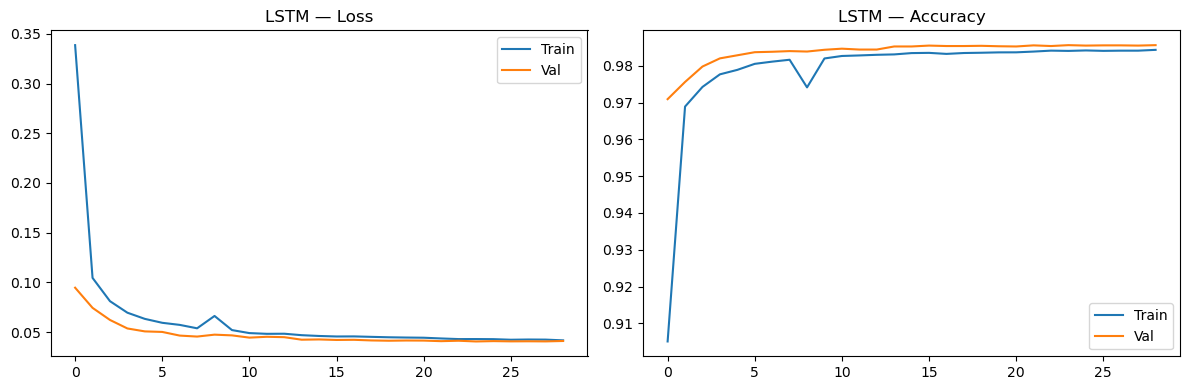

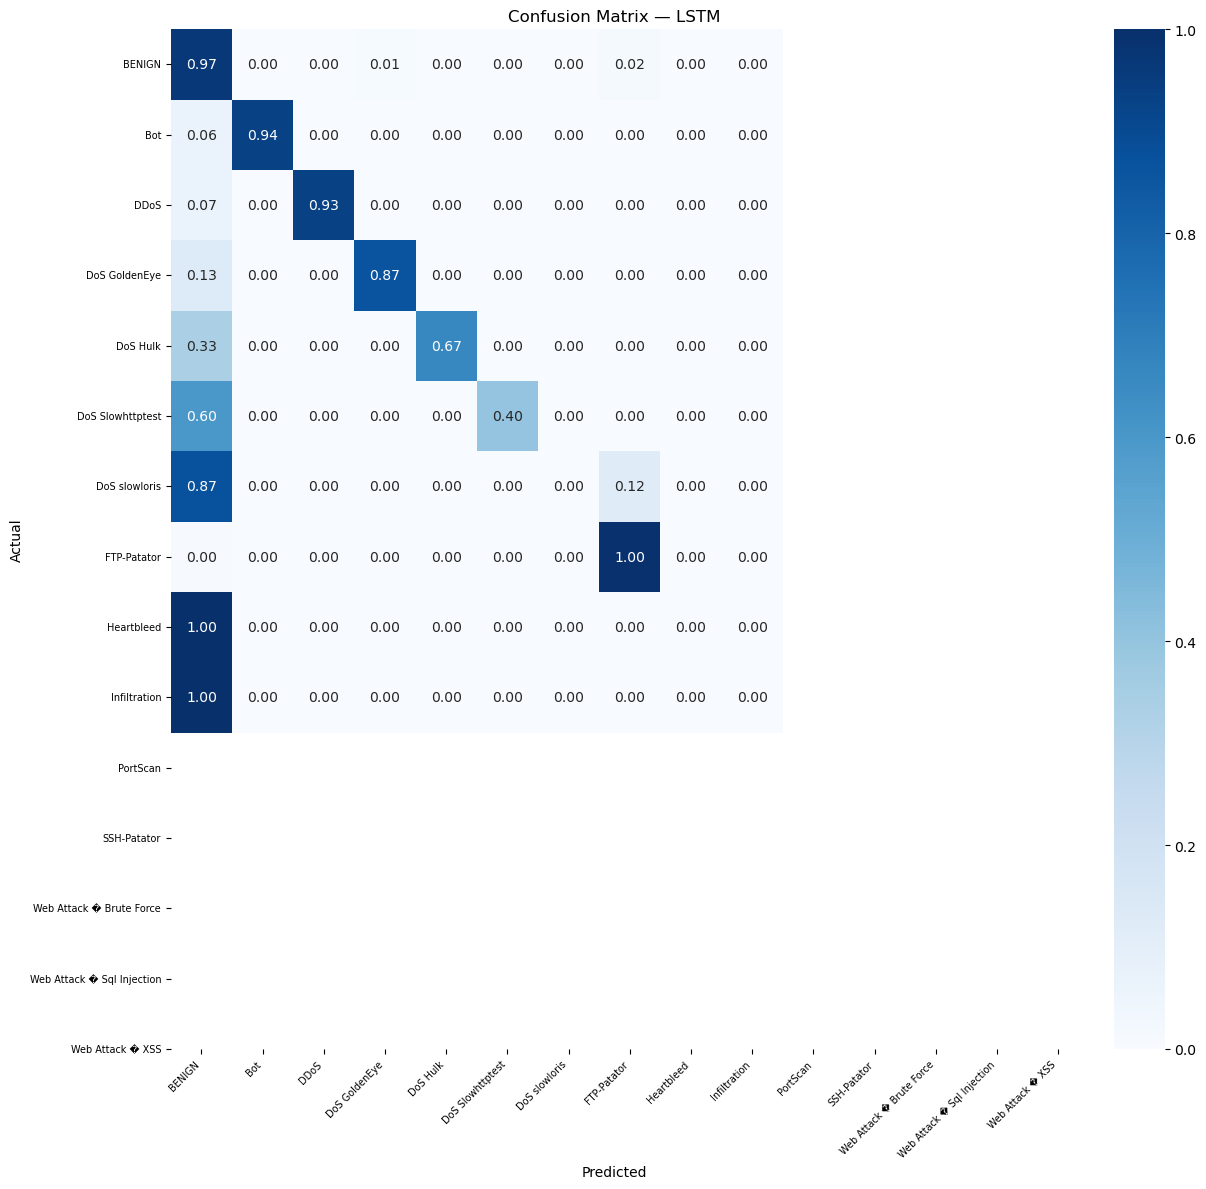

Saved -> figures/cm_lstm.png


In [44]:
plot_training_curves("LSTM", lstm_hist)
plot_cm("LSTM", y_test_lstm, lstm_pred)


## 11. Model 7 — CNN + LSTM Ensemble
*No extra training — combines both*


────────────────────────────────────────────────────
  CNN+LSTM Ensemble
────────────────────────────────────────────────────
  Accuracy  : 84.42%
  Precision : 79.78%
  Recall    : 84.42%
  F1 Score  : 81.77%
  FPR       : 4.25%
  Infer/sample: 0.40ms


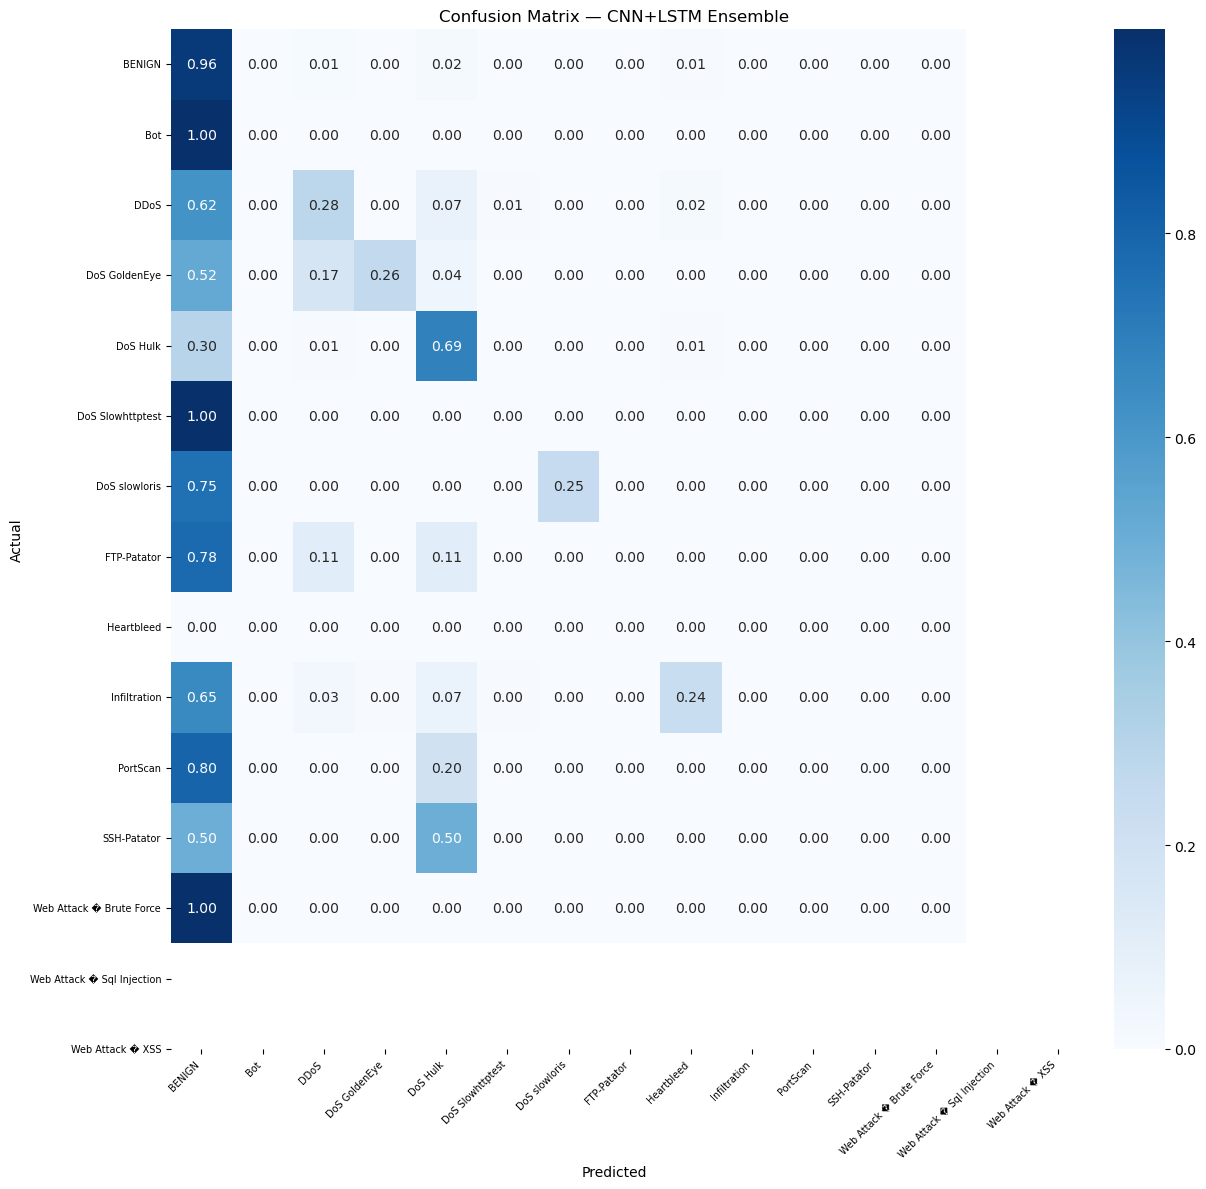

Saved -> figures/cm_cnnlstm_ensemble.png


In [45]:
# Align CNN and LSTM on the same test rows
n_lstm = len(X_test_lstm)
cnn_prob_al = cnn_prob[-n_lstm:]
y_test_al   = y_test[-n_lstm:]

ensemble_prob = (cnn_prob_al + lstm_prob) / 2.0
ensemble_pred = np.argmax(ensemble_prob, axis=1)

ens_infer = max(results["CNN"]["t_infer"], results["LSTM"]["t_infer"])
evaluate("CNN+LSTM Ensemble", y_test_al, ensemble_pred, ensemble_prob,
         t_train=None, t_infer=ens_infer)

plot_cm("CNN+LSTM Ensemble", y_test_al, ensemble_pred)


## 12. Model 8 — Transformer
*~20–45 min on CPU — most powerful model*

In [46]:
def build_transformer(ts, n_feat, n_cls,
                      d_model=64, n_heads=4, ff_dim=128, n_layers=2):
    inp = Input(shape=(ts, n_feat))
    x   = Dense(d_model)(inp)
    for _ in range(n_layers):
        attn = MultiHeadAttention(
            num_heads=n_heads, key_dim=d_model//n_heads
        )(x, x)
        x = LayerNormalization(epsilon=1e-6)(x + attn)
        ff = Dense(ff_dim, activation="relu")(x)
        ff = Dense(d_model)(ff)
        x  = LayerNormalization(epsilon=1e-6)(x + ff)
    x   = GlobalAveragePooling1D()(x)
    x   = Dropout(0.2)(x)
    x   = Dense(64, activation="relu")(x)
    out = Dense(n_cls, activation="softmax")(x)
    m   = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(5e-4),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
    return m

transformer = build_transformer(TIMESTEPS, n_features, n_classes)
transformer.summary()


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)    │ (None, 10, 77)            │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_14 (Dense)              │ (None, 10, 64)            │           4,992 │ input_layer_7[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention          │ (None, 10, 64)            │          16,640 │ dense_14[0][0],            │
│ (MultiHeadAttention)          │                           │                 │ dense_14[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 10, 64)            │               0 │ dense_14[0][0],            │
│                               │                           │                 │ multi_head_attention[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization           │ (None, 10, 64)            │             128 │ add[0][0]                  │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_15 (Dense)              │ (None, 10, 128)           │           8,320 │ layer_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_16 (Dense)              │ (None, 10, 64)            │           8,256 │ dense_15[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_1 (Add)                   │ (None, 10, 64)            │               0 │ layer_normalization[0][0], │
│                               │                           │                 │ dense_16[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_1         │ (None, 10, 64)            │             128 │ add_1[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_1        │ (None, 10, 64)            │          16,640 │ layer_normalization_1[0][… │
│ (MultiHeadAttention)          │                           │                 │ layer_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_2 (Add)                   │ (None, 10, 64)            │               0 │ layer_normalization_1[0][… │
│                               │                           │                 │ multi_head_attention_1[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_2         │ (None, 10, 64)            │             128 │ add_2[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_17 (Dense)              │ (None, 10, 128)           │           8,320 │ layer_normalization_2[0][… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 76,941 (300.55 KB)

 Trainable params: 76,941 (300.55 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
# Transformer uses same sequence format as LSTM
print("Training Transformer ...")
t0 = time.time()
trans_hist = transformer.fit(
    X_tr_lstm, y_tr_lstm,
    epochs=30, batch_size=256,
    validation_split=0.1,
    callbacks=CALLBACKS, verbose=1,
)
t_train = time.time() - t0

t1 = time.time()
trans_prob = transformer.predict(X_test_lstm, batch_size=256, verbose=0)
trans_pred = np.argmax(trans_prob, axis=1)
t_infer    = (time.time() - t1) / len(X_test_lstm)

transformer.save(f"{OUTPUT_DIR}/transformer_model.h5")
evaluate("Transformer", y_test_lstm, trans_pred, trans_prob, t_train, t_infer)


Training Transformer ...
Epoch 1/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 57s 75ms/step - accuracy: 0.9629 - loss: 0.1575 - val_accuracy: 0.2311 - val_loss: 9.0325 - learning_rate: 5.0000e-04
Epoch 2/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 41s 70ms/step - accuracy: 0.9782 - loss: 0.0771 - val_accuracy: 0.2311 - val_loss: 10.2365 - learning_rate: 5.0000e-04
Epoch 3/30
587/588 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9781 - loss: 0.0767
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
588/588 ━━━━━━━━━━━━━━━━━━━━ 42s 72ms/step - accuracy: 0.9785 - loss: 0.0745 - val_accuracy: 0.2311 - val_loss: 10.6370 - learning_rate: 5.0000e-04
Epoch 4/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 41s 70ms/step - accuracy: 0.9786 - loss: 0.0719 - val_accuracy: 0.2311 - val_loss: 11.2695 - learning_rate: 2.5000e-04
Epoch 5/30
588/588 ━━━━━━━━━━━━━━━━━━━━ 41s 70ms/step - accuracy: 0.9786 - loss: 0.0706 - val_accuracy: 0.2311 - val_loss: 11.5397 - learning_rate: 2.5000e-04
Epoch 5: early stopping
Resto


────────────────────────────────────────────────────
  Transformer
────────────────────────────────────────────────────
  Accuracy  : 80.02%
  Precision : 69.88%
  Recall    : 80.02%
  F1 Score  : 72.47%
  FPR       : 8.93%
  Train time: 223.5s
  Infer/sample: 0.37ms


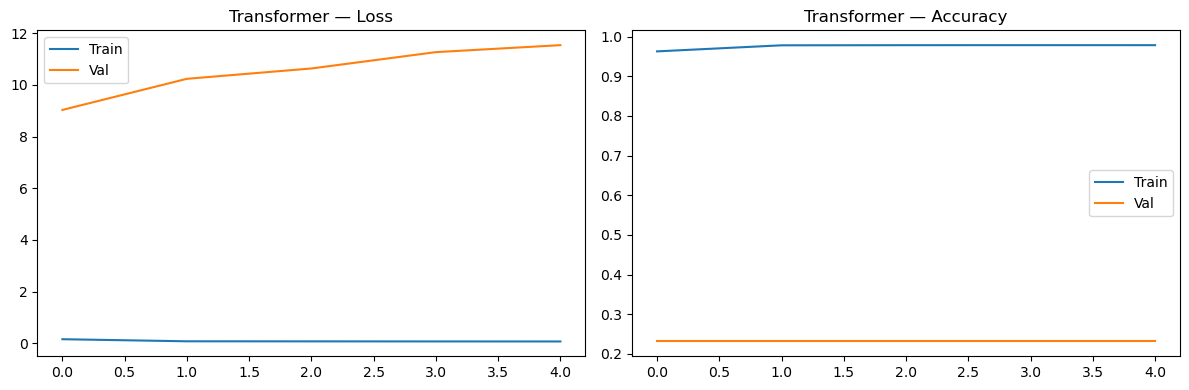

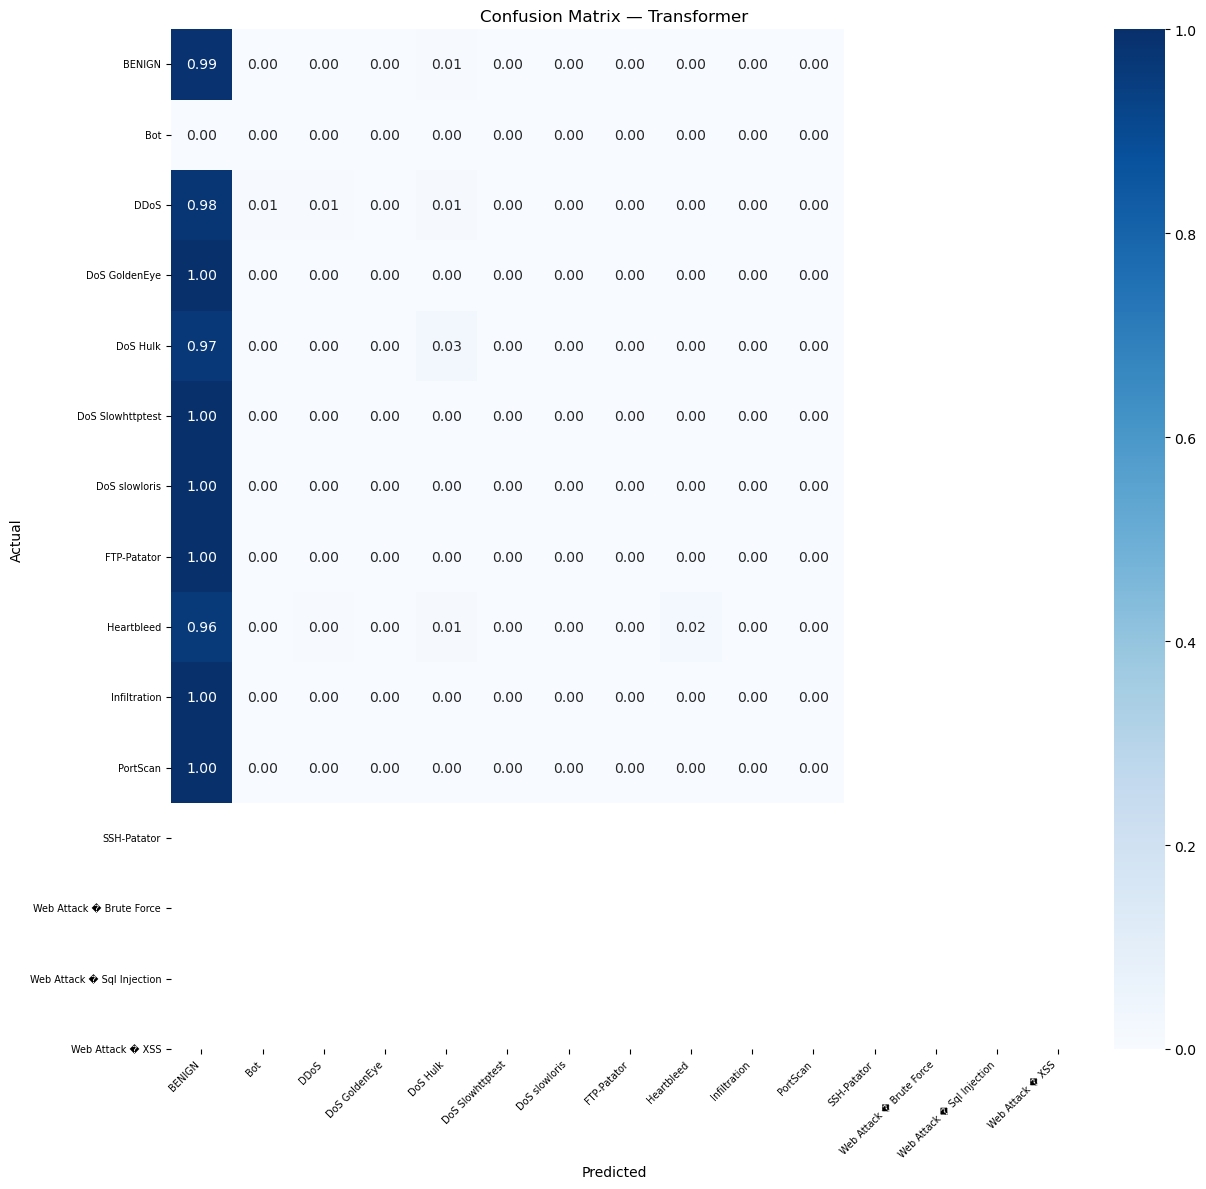

Saved -> figures/cm_transformer.png


In [48]:
plot_training_curves("Transformer", trans_hist)
plot_cm("Transformer", y_test_lstm, trans_pred)


## 13. Full Model Comparison Table & Charts

In [49]:
rows = []
for name, r in results.items():
    rows.append({
        "Model":        name,
        "Accuracy":     round(r["accuracy"]*100, 2),
        "F1 Score":     round(r["f1"]*100, 2),
        "Precision":    round(r["precision"]*100, 2),
        "Recall":       round(r["recall"]*100, 2),
        "FPR":          round(r["fpr"]*100, 2),
        "AUC-ROC":      round(r["auc"], 4) if r["auc"] else None,
        "Train (s)":    round(r["t_train"], 1) if r["t_train"] else None,
        "Infer (ms)":   round(r["t_infer"]*1000, 2) if r["t_infer"] else None,
    })

cmp_df = pd.DataFrame(rows).set_index("Model")
print("\n" + "="*70)
print("MODEL COMPARISON — CICIDS2017")
print("="*70)
display(cmp_df)

cmp_df.to_csv(f"{OUTPUT_DIR}/model_comparison.csv")
print(f"\nSaved -> {OUTPUT_DIR}/model_comparison.csv")



MODEL COMPARISON — CICIDS2017


,Accuracy,F1 Score,Precision,Recall,FPR,AUC-ROC,Train (s),Infer (ms)
Model,,,,,,,,
Random Forest,99.41,99.53,99.69,99.41,0.07,None,755.4,0.04
XGBoost,99.78,99.79,99.80,99.78,0.03,None,1100.1,0.06
SVM,72.87,79.22,92.58,72.87,2.15,None,139.4,8.23
MLP,94.00,95.37,97.34,94.00,0.50,None,1044.7,0.01
CNN,94.84,95.32,96.30,94.84,0.59,None,12263.6,0.06
LSTM,95.22,95.01,94.94,95.22,1.38,None,1035.1,0.40
CNN+LSTM Ensemble,84.42,81.77,79.78,84.42,4.25,None,NaN,0.40
Transformer,80.02,72.47,69.88,80.02,8.93,None,223.5,0.37



Saved -> models/model_comparison.csv


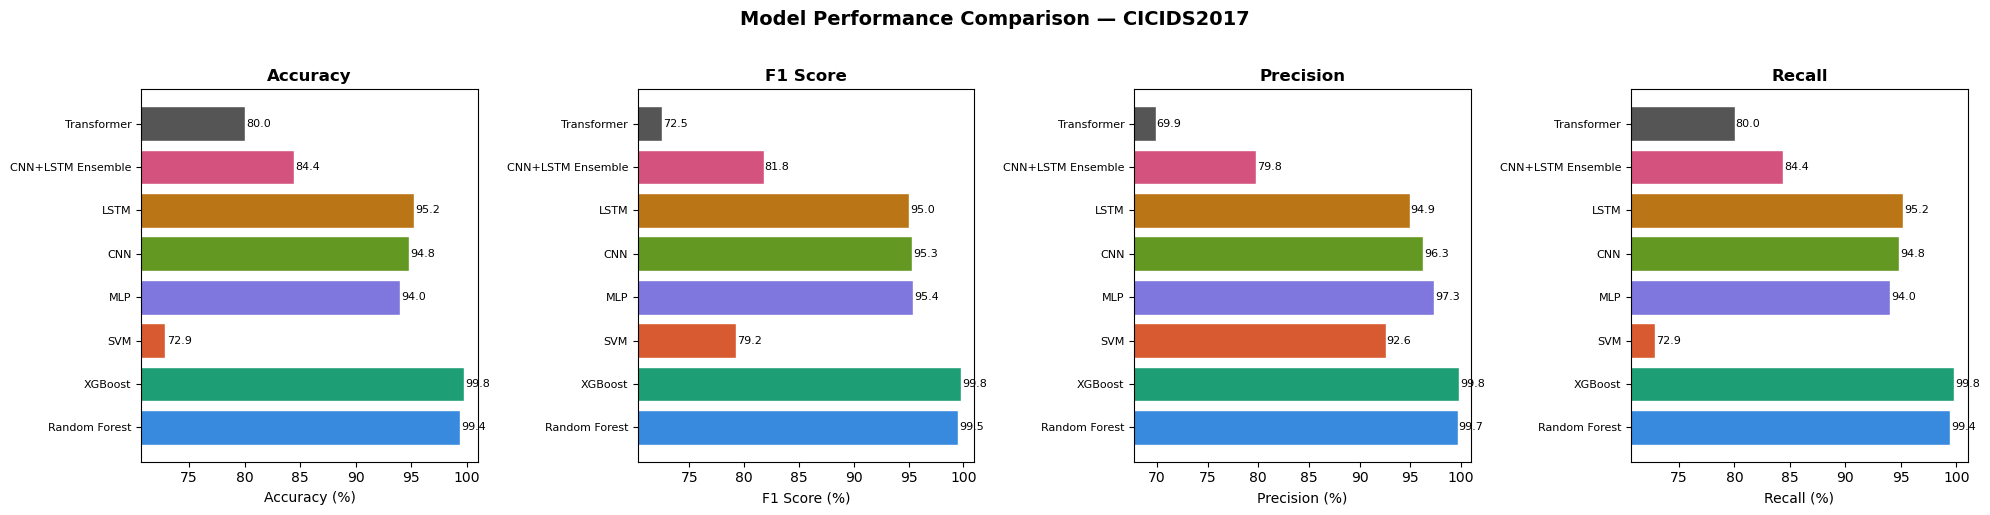

In [50]:
# Bar chart comparison
metrics = ["Accuracy","F1 Score","Precision","Recall"]
model_names_list = [r["Model"] for r in rows]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, metric in zip(axes, metrics):
    vals = [r[metric] for r in rows]
    bars = ax.barh(model_names_list, vals,
                   color=COLORS[:len(rows)], edgecolor="white")
    ax.set_xlabel(f"{metric} (%)")
    ax.set_title(metric, fontweight="bold")
    ax.set_xlim(min(vals)*0.97, 101)
    for bar, val in zip(bars, vals):
        ax.text(val+0.1, bar.get_y()+bar.get_height()/2,
                f"{val:.1f}", va="center", fontsize=8)
    ax.tick_params(axis="y", labelsize=8)

plt.suptitle("Model Performance Comparison — CICIDS2017",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/model_comparison_bars.png", dpi=150, bbox_inches="tight")
plt.show()


  ROC skipped for Random Forest: index 14 is out of bounds for axis 1 with size 13
  ROC skipped for SVM: index 14 is out of bounds for axis 1 with size 13
  ROC skipped for MLP: index 14 is out of bounds for axis 1 with size 13
  ROC skipped for CNN+LSTM Ensemble: index 14 is out of bounds for axis 1 with size 13


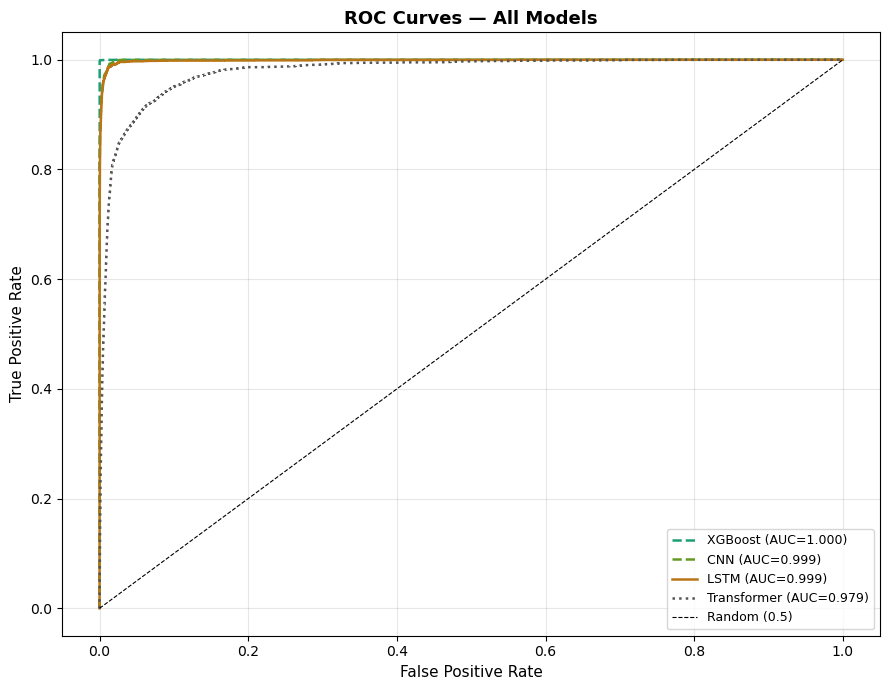

In [51]:
# ROC curves — all models overlaid
fig, ax = plt.subplots(figsize=(9, 7))
styles = ["-","--","-.",":","--","-","-.",":"]

for i, (name, r) in enumerate(results.items()):
    if r["y_prob"] is None: continue
    yt = r["y_true"]
    try:
        yt_bin = to_categorical(yt, n_classes)
        yp     = r["y_prob"]
        if yt_bin.shape[0] != yp.shape[0]: continue
        fpr_v, tpr_v, _ = roc_curve(yt_bin.ravel(), yp.ravel())
        auc_v = auc(fpr_v, tpr_v)
        ax.plot(fpr_v, tpr_v,
                lw=1.8, ls=styles[i%len(styles)],
                color=COLORS[i%len(COLORS)],
                label=f"{name} (AUC={auc_v:.3f})")
    except Exception as e:
        print(f"  ROC skipped for {name}: {e}")

ax.plot([0,1],[0,1],"k--",lw=0.8,label="Random (0.5)")
ax.set_xlabel("False Positive Rate", fontsize=11)
ax.set_ylabel("True Positive Rate", fontsize=11)
ax.set_title("ROC Curves — All Models", fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/roc_all_models.png", dpi=150)
plt.show()


## 14. Cross-Dataset Generalisation — UNSW-NB15
Train on CICIDS2017, test on UNSW-NB15 without retraining.  
This is the key academic contribution — proves behavioral generalisation.


In [52]:
def load_unsw(tr_path, te_path):
    for p in (tr_path, te_path):
        if not os.path.exists(p):
            print(f"  Not found: {p}")
            return None, None
    df = pd.concat([
        pd.read_csv(tr_path, low_memory=False),
        pd.read_csv(te_path,  low_memory=False),
    ], ignore_index=True)
    df.columns = df.columns.str.strip().str.lower()
    df.replace([np.inf,-np.inf], np.nan, inplace=True)
    df.dropna(inplace=True)

    # Binary label: 0=normal, 1=attack
    if "label" in df.columns:
        y = df["label"].astype(int).values
    elif "attack_cat" in df.columns:
        y = (df["attack_cat"].str.strip().str.lower() != "normal").astype(int).values
    else:
        print("  No label column found in UNSW-NB15")
        return None, None

    drop = ["srcip","sport","dstip","dsport","stime","ltime",
            "attack_cat","label","id","proto","service","state"]
    df_feat = df.drop(columns=[c for c in drop if c in df.columns], errors="ignore")
    df_feat = df_feat.select_dtypes(include=[np.number])
    df_feat.replace([np.inf,-np.inf], np.nan, inplace=True)
    df_feat.dropna(inplace=True)
    y = y[df_feat.index]
    X = df_feat.values.astype(np.float32)
    print(f"  UNSW-NB15: {X.shape[0]:,} samples, {X.shape[1]} features")
    return X, y

print("Loading UNSW-NB15 ...")
X_unsw, y_unsw = load_unsw(UNSW_TRAIN, UNSW_TEST)


Loading UNSW-NB15 ...
  UNSW-NB15: 257,673 samples, 39 features


In [54]:
if X_unsw is not None:
    # Align feature count
    if X_unsw.shape[1] < n_features:
        pad = np.zeros((X_unsw.shape[0], n_features - X_unsw.shape[1]), dtype=np.float32)
        X_unsw_al = np.hstack([X_unsw, pad])
    else:
        X_unsw_al = X_unsw[:, :n_features]

    X_unsw_sc = scaler.transform(X_unsw_al)
    cross = {}

    # RF
    pred = (rf.predict(X_unsw_sc) > 0).astype(int)
    cross["Random Forest"] = {
        "acc": accuracy_score(y_unsw, pred),
        "f1":  f1_score(y_unsw, pred, average="weighted", zero_division=0)
    }

    # XGB — fixed variable name
    pred = (xgb_model.predict(X_unsw_sc) > 0).astype(int)
    cross["XGBoost"] = {
        "acc": accuracy_score(y_unsw, pred),
        "f1":  f1_score(y_unsw, pred, average="weighted", zero_division=0)
    }

    # CNN
    pred = (np.argmax(cnn.predict(
        X_unsw_sc.reshape(-1, n_features, 1), verbose=0
    ), axis=1) > 0).astype(int)
    cross["CNN"] = {
        "acc": accuracy_score(y_unsw, pred),
        "f1":  f1_score(y_unsw, pred, average="weighted", zero_division=0)
    }

    # LSTM — fixed to use make_sequences_clean
    X_u_seq, y_u_seq = make_sequences_clean(X_unsw_sc, y_unsw, TIMESTEPS)
    pred = (np.argmax(lstm.predict(X_u_seq, verbose=0), axis=1) > 0).astype(int)
    cross["LSTM"] = {
        "acc": accuracy_score(y_u_seq, pred),
        "f1":  f1_score(y_u_seq, pred, average="weighted", zero_division=0)
    }

    # Transformer — same sequences as LSTM
    pred = (np.argmax(transformer.predict(X_u_seq, verbose=0), axis=1) > 0).astype(int)
    cross["Transformer"] = {
        "acc": accuracy_score(y_u_seq, pred),
        "f1":  f1_score(y_u_seq, pred, average="weighted", zero_division=0)
    }

    print("\nCross-dataset results (CICIDS2017 trained → UNSW-NB15 tested):")
    print(f"{'Model':<25} {'Accuracy':>10} {'F1':>10}")
    print("─"*48)
    for m, v in cross.items():
        print(f"  {m:<23} {v['acc']*100:>9.1f}% {v['f1']*100:>9.1f}%")

else:
    print("UNSW-NB15 not found — skipping cross-dataset test.")
    cross = {}


Cross-dataset results (CICIDS2017 trained → UNSW-NB15 tested):
Model                       Accuracy         F1
────────────────────────────────────────────────
  Random Forest                36.1%      19.1%
  XGBoost                      36.1%      19.1%
  CNN                          36.0%      19.1%
  LSTM                         58.9%      51.1%
  Transformer                  33.7%      34.2%


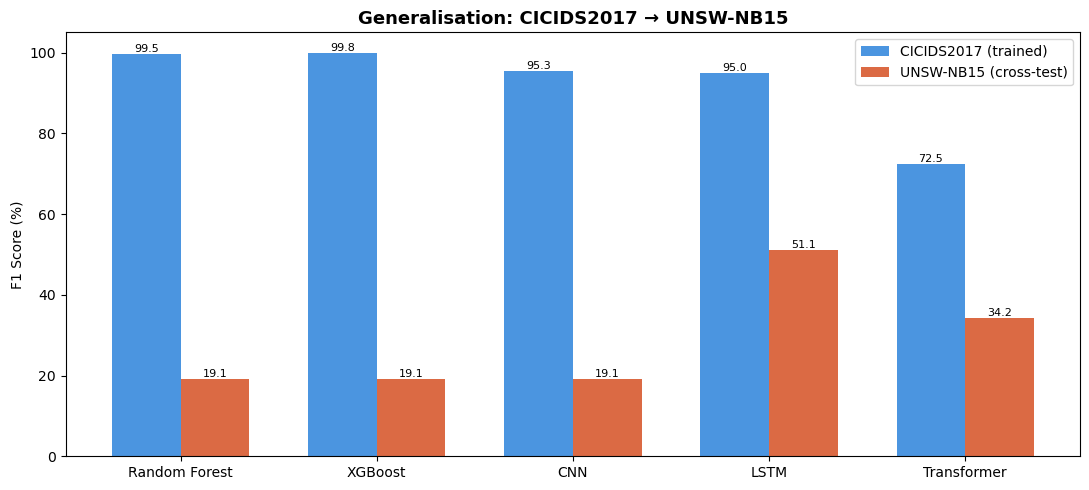

Deep learning models should show a smaller drop than RF/XGBoost.
That gap IS the thesis of your paper.


In [55]:
# Cross-dataset bar chart
if cross:
    names_c = list(cross.keys())
    cicids_f1 = [results[n]["f1"]*100 if n in results else 0 for n in names_c]
    unsw_f1   = [cross[n]["f1"]*100 for n in names_c]

    x = np.arange(len(names_c))
    w = 0.35
    fig, ax = plt.subplots(figsize=(11, 5))
    b1 = ax.bar(x-w/2, cicids_f1, w, label="CICIDS2017 (trained)",
                color="#378ADD", alpha=0.9)
    b2 = ax.bar(x+w/2, unsw_f1,   w, label="UNSW-NB15 (cross-test)",
                color="#D85A30", alpha=0.9)
    ax.set_xticks(x); ax.set_xticklabels(names_c, fontsize=10)
    ax.set_ylabel("F1 Score (%)"); ax.set_ylim(0,105)
    ax.set_title("Generalisation: CICIDS2017 → UNSW-NB15",
                 fontsize=13, fontweight="bold")
    ax.legend()
    for bar in list(b1)+list(b2):
        h = bar.get_height()
        ax.text(bar.get_x()+bar.get_width()/2, h+0.5,
                f"{h:.1f}", ha="center", fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/cross_dataset.png", dpi=150)
    plt.show()
    print("Deep learning models should show a smaller drop than RF/XGBoost.")
    print("That gap IS the thesis of your paper.")


## 15. Final Summary & Files Saved

In [56]:
print("\n" + "="*65)
print("FINAL RESULTS — CICIDS2017")
print("="*65)
print(f"{'Model':<25} {'Acc':>7} {'F1':>7} {'FPR':>7} {'AUC':>7}")
print("─"*65)
for name, r in results.items():
    auc_s = f"{r['auc']:.3f}" if r["auc"] else "  —  "
    print(f"  {name:<23} "
          f"{r['accuracy']*100:>6.2f}% "
          f"{r['f1']*100:>6.2f}% "
          f"{r['fpr']*100:>6.2f}% "
          f"{auc_s:>7}")

print("\n" + "="*65)
print("FILES SAVED")
print("="*65)
saved = [
    "models/rf_model.pkl",
    "models/xgb_model.pkl",
    "models/svm_model.pkl",
    "models/mlp_model.pkl",
    "models/cnn_model.h5",
    "models/lstm_model.h5",
    "models/transformer_model.h5",
    "models/scaler.pkl",
    "models/label_encoder.pkl",
    "models/model_comparison.csv",
    "figures/  (all plots)",
]
for s in saved:
    print(f"  {s}")

print("\nNEXT STEP:")
print("  Plug cnn_model.h5 + lstm_model.h5 + scaler.pkl")
print("  into the live IDS detector module.")
print("  The live capture feeds each completed flow through")
print("  the same scaler → CNN+LSTM ensemble → alert.")



FINAL RESULTS — CICIDS2017
Model                         Acc      F1     FPR     AUC
─────────────────────────────────────────────────────────────────
  Random Forest            99.41%  99.53%   0.07%     —  
  XGBoost                  99.78%  99.79%   0.03%     —  
  SVM                      72.87%  79.22%   2.15%     —  
  MLP                      94.00%  95.37%   0.50%     —  
  CNN                      94.84%  95.32%   0.59%     —  
  LSTM                     95.22%  95.01%   1.38%     —  
  CNN+LSTM Ensemble        84.42%  81.77%   4.25%     —  
  Transformer              80.02%  72.47%   8.93%     —  

FILES SAVED
  models/rf_model.pkl
  models/xgb_model.pkl
  models/svm_model.pkl
  models/mlp_model.pkl
  models/cnn_model.h5
  models/lstm_model.h5
  models/transformer_model.h5
  models/scaler.pkl
  models/label_encoder.pkl
  models/model_comparison.csv
  figures/  (all plots)

NEXT STEP:
  Plug cnn_model.h5 + lstm_model.h5 + scaler.pkl
  into the live IDS detector module.
  The 